In [1]:
import numpy as np
import re
import math
import sys
from collections import defaultdict, Counter
import json
import itertools
import warnings
import statistics
from pathlib import Path
import zipfile
from scipy import interpolate
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
def notebook_path_on_disk():
    return Path(json.loads(Path(sys.argv[-1]).read_bytes())['jupyter_session'])

modification_data = {
    'short_across_traces': [31, 32, 33, 34, 35],
    'short_within_trace': [26, 27, 28, 29, 30],
    'open': [21, 22, 23, 24, 25],
}

def load_multichannel_data(path=None):
    if path is None:
        # Get the data dir independent on where exactly the Jupyter server is running
        path = notebook_path_on_disk().parent.parent / 'data_multi'
        
    data_dict = defaultdict(list)
    for le_zip in path.glob('*.zip'):
        le_zip = zipfile.ZipFile(le_zip)
        for entry in le_zip.infolist():
            if not entry.filename.endswith('.json'):
                continue
            data = json.loads(le_zip.read(entry))
            info = data['info']
            meta, specimen = info['meta'], info['specimen']
            mesh_id = specimen
            _rest, _, serial = specimen.rpartition('-')
            try:
                serial = int(serial)
            except:
                serial = 'none'

            mods = []
            for modification, matching_serials in modification_data.items():
                if serial in matching_serials:
                    mods.append(modification)
            info['mods'] = mods

            if (g := re.search(r'p([.0-9]+)', meta)):
                pitch = str(float(*g.groups()))
            else:
                warnings.warn(f'Unknown pitch for {meta!r}')
                pitch = '?'

            mesh_layout = re.sub(r'-\d{4}', '', specimen)
            
            if (g := re.search(r'side-([ab])-(right|left)', meta)):
                layer, half = g.groups()
                mesh_id = f'M-{specimen}-{pitch}-{layer}-{half}'
                mesh_layout += f'-{layer}-{half}'
            else:
                mesh_id = f'M-{specimen}-{pitch}'
            info['mesh_id'] = mesh_id
            info['mesh_layout'] = mesh_layout
            info['pitch'] = pitch
            info['serial'] = serial if serial != 'none' else 0
            data_dict[mesh_id].append(data)
    return data_dict

data = load_multichannel_data()

/tmp/ipykernel_789915/2647136726.py:40: UserWarning: Unknown pitch for 'baseline-5-open'
  warnings.warn(f'Unknown pitch for {meta!r}')


In [3]:
def newest_for_mesh(chip='pi3hdx12211'):
    out = {}
    for key, entries in data.items():
        entries = [e for e in entries if e['info']['chip'] == chip]
        out[key] = entries[0]
        for value in entries[1:]:
            if value['info']['timestamp'] > out[key]['info']['timestamp']:
                out[key] = value
    return out

data_newest = newest_for_mesh()
mod_baseline = {pitch: [
                        data_newest[f'M-SP-PITCH-V2-{serial:04d}-{pitch}']
                        for serial in [6, 7, 8, 9, 10]]
                for pitch in [0.3, 0.4, 0.6, 1.0]}

mod_modified = {(mod, pitch): [
                        value
                        for value in data_newest.values()
                        if mod in value['info']['mods']
                        and value['info']['pitch'] == str(pitch)]
                for mod, pitch in itertools.product(['open', 'short_within_trace', 'short_across_traces'],
                                                    [0.3, 0.4, 0.6, 1.0])}

#{k: [e['info']['timestamp'] for e in v] for k, v in mod_baseline.items()}
{k: [e['info']['meta'] for e in v] for k, v in mod_modified.items()}

{('open', 0.3): ['mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3'],
 ('open', 0.4): ['mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4'],
 ('open', 0.6): ['mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6'],
 ('open', 1.0): ['mods-25-07-01-01-p1.0',
  'mods-25-07-01-01-p1.0',
  'mods-25-07-01-01-p1.0',
  'mods-25-07-01-01-p1.0',
  'mods-25-07-01-01-p1.0'],
 ('short_within_trace', 0.3): ['mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3'],
 ('short_within_trace', 0.4): ['mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4'],
 ('short_within_trace', 0.6): ['mods-25-07-01-01-p0.6',
  'mods-25

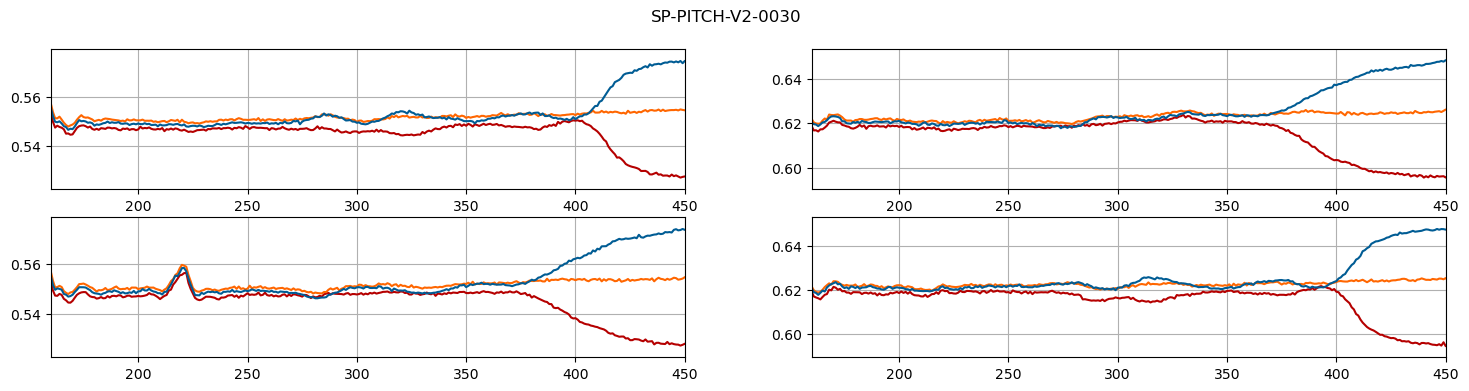

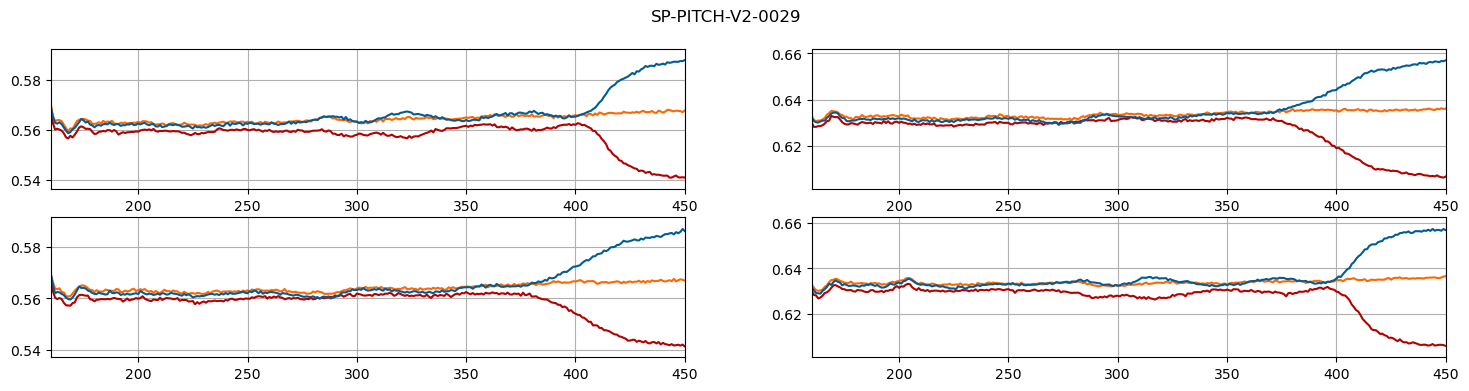

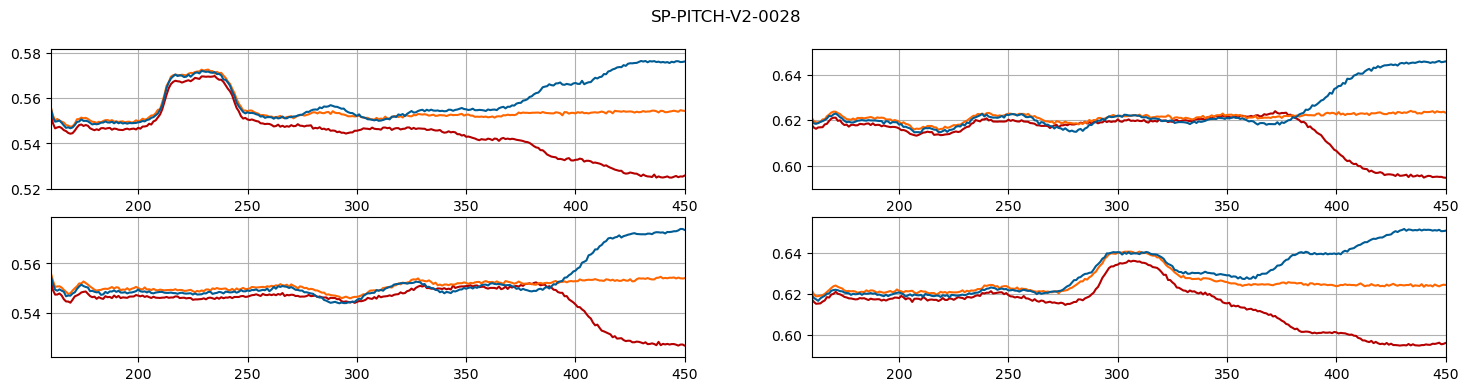

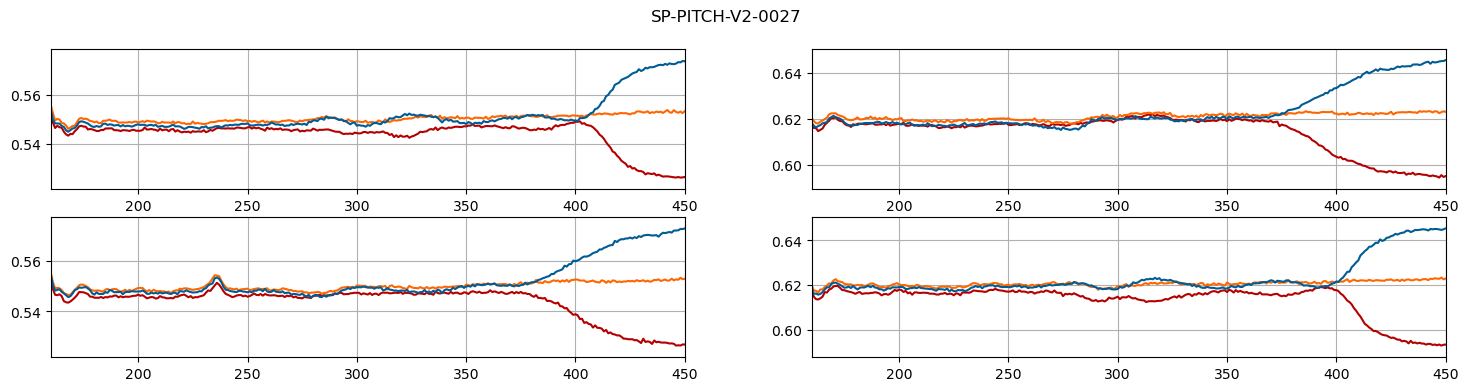

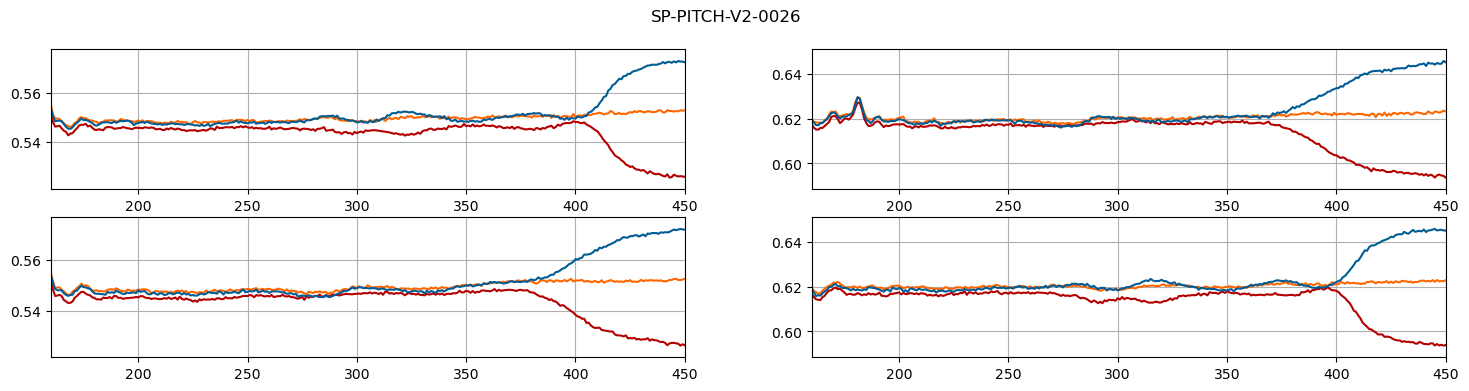

In [29]:
color_palette = [(181/255, 0.0, 0.0), (1.0, 102/255, 0.0), (0.0, 92/255, 148/255)]

def view_trace(trace):
    fig, axs = plt.subplots(2, 2, figsize=(18, 4))
    fig.suptitle(trace['info']['specimen'])
    for i, direction in enumerate(['fwd', 'flip']):
        for j, adc in enumerate(['adc1', 'adc2']):
            axs[i, j].grid()
            a, b = 160, 450
            axs[i,j].set_xlim([a, b])
            axs[i,j].set_ylim([0.5, 0.65])
            min_y = 1e9
            max_y = -1e9
            for color, load in zip(color_palette, ['open', 'short', 'load']):
                adc_trace = np.array(trace['data'][f'{load}_{direction}'][adc])
                var_trace = np.array(trace['data'][f'{load}_{direction}'][adc.replace('adc', 'var')])
                min_y = min(min_y, (adc_trace - var_trace)[a:b].min())
                max_y = max(max_y, (adc_trace + var_trace)[a:b].max())
                axs[i,j].plot(adc_trace, color=color)
                axs[i,j].fill_between(adc_trace + var_trace, adc_trace - var_trace, color=color, alpha=0.3)
            dy = max_y - min_y
            axs[i, j].set_ylim([min_y - 0.1*dy, max_y + 0.1*dy])

view_trace(mod_modified[('short_within_trace', 0.3)][0])
view_trace(mod_modified[('short_within_trace', 0.3)][1])
view_trace(mod_modified[('short_within_trace', 0.3)][2])
view_trace(mod_modified[('short_within_trace', 0.3)][3])
view_trace(mod_modified[('short_within_trace', 0.3)][4])